# Notebook 02 — DNN Architecture and Training

**Project:** Student Academic Performance Prediction  
**Objective:** Predict **Low / Average / Good** final performance using student details available **after G2**.

### What this notebook does
1. Load the exact 12 features selected in Notebook 01.
2. Recreate the same train/validation/test split.
3. Fit preprocessing **only on training data**.
4. Build and train a simple Deep Neural Network (DNN).
5. Inspect learning curves and **validation** performance.
6. Save the trained DNN and preprocessor as **initial training artifacts**.

**Important:** The 130-row test set is deliberately not evaluated here. Notebook 03 will tune the DNN; final test evaluation happens only after model selection.


## 1. Import libraries

We use pandas for data, scikit-learn for preprocessing/splitting, and TensorFlow/Keras for the neural network.

If packages are missing, run this in your project terminal (not inside a notebook cell):

```bash
python -m pip install pandas numpy matplotlib scikit-learn tensorflow joblib
```

In [1]:
from pathlib import Path
import json
import random

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

DATA_PATH = Path("../data/student-por.csv")
CONFIG_PATH = Path("../models/selected_features.json")
MODELS_DIR = Path("../models")

assert DATA_PATH.exists(), f"Missing dataset: {DATA_PATH}"
assert CONFIG_PATH.exists(), (
    "Missing models/selected_features.json. Run Notebook 01 first."
)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Load data and selected features

**Why?** Notebook 01 already selected 12 inputs. We must use the **same inputs** throughout the DNN, Logistic Regression and Random Forest experiments.

`G3` is used only to create the target label; it is never an input.

In [2]:
df = pd.read_csv(DATA_PATH, sep=";")
config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
selected_features = config["selected_features"]

def performance_category(g3):
    if g3 < 10:
        return "Low"
    if g3 < 14:
        return "Average"
    return "Good"

df["performance_category"] = df["G3"].apply(performance_category)
X = df[selected_features].copy()
y = df["performance_category"].copy()

assert len(selected_features) == 12
assert {"G1", "G2"}.issubset(selected_features)
assert "G3" not in selected_features
assert not X.isna().any().any(), "Missing values require train-only imputation."

print("Selected features:", selected_features)
print("Input shape:", X.shape)
display(X.head())
display(y.value_counts().rename("students").to_frame())

Selected features: ['G1', 'G2', 'failures', 'higher', 'absences', 'studytime', 'school', 'Fedu', 'Medu', 'Mjob', 'Dalc', 'famrel']
Input shape: (649, 12)


,G1,G2,failures,higher,absences,studytime,school,Fedu,Medu,Mjob,Dalc,famrel
0,0,11,0,yes,4,2,GP,4,4,at_home,1,4
1,9,11,0,yes,2,2,GP,1,1,at_home,1,5
2,12,13,0,yes,6,2,GP,1,1,at_home,2,4
3,14,14,0,yes,0,3,GP,2,4,health,1,3
4,11,13,0,yes,0,2,GP,3,3,other,1,4


,students
performance_category,
Average,355
Good,194
Low,100


## 3. Recreate exactly the same data split

**Why?** A fair comparison requires consistent data splits.

- Train: **415** students — learn model parameters
- Validation: **104** students — inspect performance and guide tuning
- Test: **130** students — reserved for the final evaluation

We create the test split here but **do not use it for model training, tuning, metrics or plots**.

In [3]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=SEED, stratify=y_dev
)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Reserved test:", X_test.shape)
assert (len(X_train), len(X_val), len(X_test)) == (415, 104, 130)

Training: (415, 12)
Validation: (104, 12)
Reserved test: (130, 12)


## 4. Preprocess numerical and categorical features

**Why two methods?**
- `StandardScaler`: numerical features ko comparable scale par laata hai.
- `OneHotEncoder`: text categories ko numerical columns mein convert karta hai.

**Leakage prevention:** `fit_transform` **only on training rows**. Validation rows use `transform` only.

**Note:** This preprocessing is for model training. Notebook 01's ordinal encoding was used only for Mutual Information ranking.

In [4]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Compatible with both recent and older scikit-learn versions.
try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", one_hot, categorical_features),
    ],
    remainder="drop",
)

X_train_processed = preprocessor.fit_transform(X_train).astype("float32")
X_val_processed = preprocessor.transform(X_val).astype("float32")

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_val_encoded = label_encoder.transform(y_val)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)
print("Processed training shape:", X_train_processed.shape)
print("Class mapping:", dict(enumerate(label_encoder.classes_)))
assert X_train_processed.shape[0] == len(y_train)
assert X_val_processed.shape[0] == len(y_val)
assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_val_processed).all()

Numerical features: ['G1', 'G2', 'failures', 'absences', 'studytime', 'Fedu', 'Medu', 'Dalc', 'famrel']
Categorical features: ['higher', 'school', 'Mjob']
Processed training shape: (415, 18)
Class mapping: {0: 'Average', 1: 'Good', 2: 'Low'}


## 5. Design the DNN

**Architecture:**

`Input → Dense(64, ReLU) → Dropout(0.2) → Dense(32, ReLU) → Dropout(0.2) → Dense(3, Softmax)`

- **Dense:** Learns patterns from student information.
- **ReLU:** Introduces non-linearity.
- **Dropout:** Helps reduce overfitting.
- **Softmax:** Produces three class probabilities that sum to 1.
- **Sparse categorical cross-entropy:** Correct loss for integer-encoded multi-class labels.

This is our **starting architecture**, not a tuned optimum.

In [5]:
def build_dnn(input_dim, learning_rate=0.001, dropout_rate=0.2):
    model = Sequential([
        Input(shape=(input_dim,)),
        Dense(64, activation="relu"),
        Dropout(dropout_rate),
        Dense(32, activation="relu"),
        Dropout(dropout_rate),
        Dense(3, activation="softmax"),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_dnn(X_train_processed.shape[1])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,395 (13.26 KB)

 Trainable params: 3,395 (13.26 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the DNN

**Why early stopping?** Agar validation loss improve hona band ho jaaye, training stop kar denge to reduce unnecessary overfitting.

We monitor `val_loss` and restore the best validation-loss weights.

We are **not** using the reserved test set.

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
)

history = model.fit(
    X_train_processed,
    y_train_encoded,
    validation_data=(X_val_processed, y_val_encoded),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)

print("Epochs completed:", len(history.history["loss"]))

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step - accuracy: 0.4241 - loss: 1.1068 - val_accuracy: 0.5192 - val_loss: 0.9574
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5542 - loss: 0.9583 - val_accuracy: 0.6731 - val_loss: 0.8484
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6361 - loss: 0.8336 - val_accuracy: 0.7885 - val_loss: 0.7563
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7036 - loss: 0.7427 - val_accuracy: 0.7692 - val_loss: 0.6811
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7253 - loss: 0.6769 - val_accuracy: 0.7596 - val_loss: 0.6252
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7470 - loss: 0.6023 - val_accuracy: 0.7596 - val_loss: 0.5875
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7446 - loss: 0.6000 - val_accuracy: 0.7692 - val_loss: 0.5582
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7566 - loss: 0.5436 - val_accuracy: 0.

## 7. Plot training and validation curves

**What to look for:**
- Training loss generally decreases as the model learns.
- Validation loss helps us spot overfitting.
- A large training-vs-validation accuracy gap can indicate overfitting.

These plots are diagnostics, not final test results.

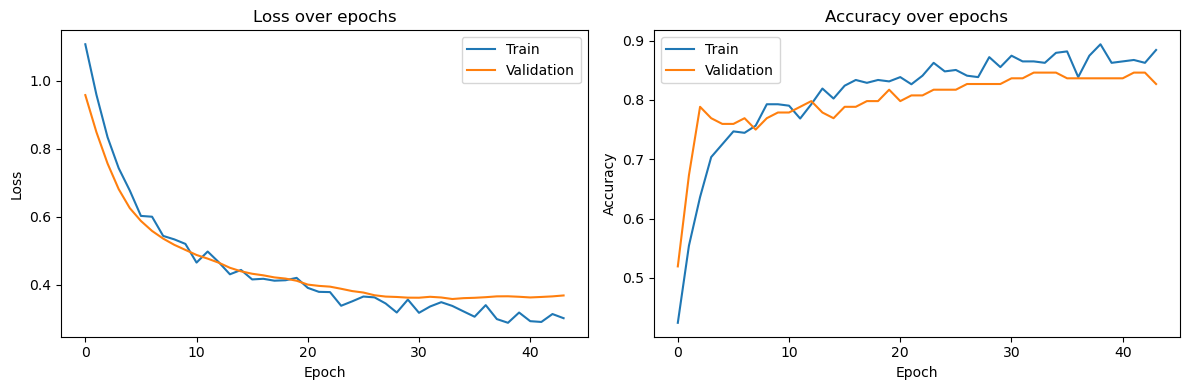

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train")
axes[0].plot(history.history["val_loss"], label="Validation")
axes[0].set(title="Loss over epochs", xlabel="Epoch", ylabel="Loss")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train")
axes[1].plot(history.history["val_accuracy"], label="Validation")
axes[1].set(title="Accuracy over epochs", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

## 8. Evaluate on validation data only

We report:
- **Accuracy:** Overall correct predictions.
- **Macro F1:** Gives equal importance to all three classes.
- **Low-class recall:** How many actual Low-performing students were correctly identified.
- **Confusion matrix:** Which classes are being confused.

The dataset has more Average students than Low students, so macro F1 and Low recall are especially useful.

**Do not report these validation scores as final test performance.**

Validation accuracy: 84.62%
Validation macro F1: 81.68%
Validation Low-class recall: 68.75%

Classification report:
              precision    recall  f1-score   support

         Low       0.69      0.69      0.69        16
     Average       0.86      0.86      0.86        57
        Good       0.90      0.90      0.90        31

    accuracy                           0.85       104
   macro avg       0.82      0.82      0.82       104
weighted avg       0.85      0.85      0.85       104



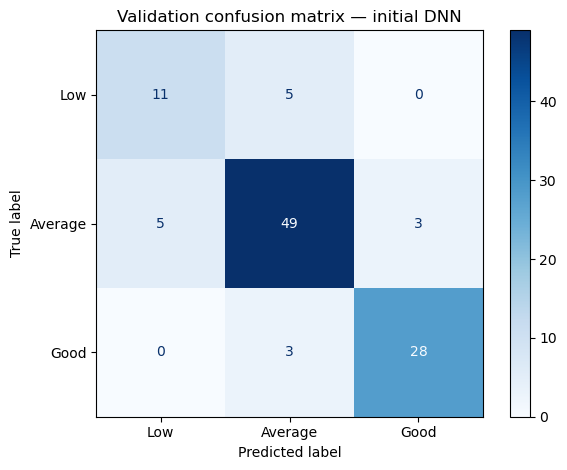

In [8]:
val_probabilities = model.predict(X_val_processed, verbose=0)
val_pred_encoded = np.argmax(val_probabilities, axis=1)
val_pred = label_encoder.inverse_transform(val_pred_encoded)

accuracy = accuracy_score(y_val, val_pred)
macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)
report = classification_report(
    y_val, val_pred, labels=["Low", "Average", "Good"],
    output_dict=True, zero_division=0
)
low_recall = report["Low"]["recall"]

print(f"Validation accuracy: {accuracy:.2%}")
print(f"Validation macro F1: {macro_f1:.2%}")
print(f"Validation Low-class recall: {low_recall:.2%}")
print("\nClassification report:")
print(classification_report(
    y_val, val_pred, labels=["Low", "Average", "Good"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_val, val_pred, labels=["Low", "Average", "Good"],
    cmap="Blues", values_format="d"
)
plt.title("Validation confusion matrix — initial DNN")
plt.tight_layout()
plt.show()

## 9. Save initial training artifacts

Notebook 03 will tune the DNN. To avoid confusing an **initial model** with the **final model**, we save with the prefix `initial_dnn_`.

The preprocessor and label encoder are saved because the Streamlit app must apply exactly the same transformations as training.

**Security:** Only load `.joblib` files created by your own trusted project; joblib files can execute code when loaded.

In [9]:
model.save(MODELS_DIR / "initial_dnn.keras")
joblib.dump(preprocessor, MODELS_DIR / "initial_dnn_preprocessor.joblib")
joblib.dump(label_encoder, MODELS_DIR / "initial_dnn_label_encoder.joblib")

metadata = {
    "model_stage": "initial_dnn_before_tuning",
    "dataset": "student-por.csv",
    "seed": SEED,
    "selected_features": selected_features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "class_names": label_encoder.classes_.tolist(),
    "validation_accuracy": float(accuracy),
    "validation_macro_f1": float(macro_f1),
    "validation_low_recall": float(low_recall),
    "architecture": "64-ReLU / Dropout / 32-ReLU / Dropout / 3-Softmax",
    "learning_rate": 0.001,
    "dropout_rate": 0.2,
    "batch_size": 32,
    "test_set_evaluated": False,
}
(MODELS_DIR / "initial_dnn_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)
print("Saved initial model, preprocessor, encoder and metadata to models/.")

Saved initial model, preprocessor, encoder and metadata to models/.


## 10. Verify saved artifacts

A saved model is useful only if it can be loaded and gives the same predictions.

We compare the loaded model's probabilities against the in-memory model on **validation data**.

In [10]:
reloaded_model = tf.keras.models.load_model(MODELS_DIR / "initial_dnn.keras")
reloaded_preprocessor = joblib.load(MODELS_DIR / "initial_dnn_preprocessor.joblib")
reloaded_encoder = joblib.load(MODELS_DIR / "initial_dnn_label_encoder.joblib")

reloaded_X_val = reloaded_preprocessor.transform(X_val).astype("float32")
reloaded_probabilities = reloaded_model.predict(reloaded_X_val, verbose=0)

np.testing.assert_allclose(
    reloaded_probabilities, val_probabilities, rtol=1e-5, atol=1e-6
)
assert reloaded_encoder.classes_.tolist() == label_encoder.classes_.tolist()
print("PASS — Saved model and preprocessing reload correctly.")
print("Next: Notebook 03 — DNN Hyperparameter Tuning.")

PASS — Saved model and preprocessing reload correctly.
Next: Notebook 03 — DNN Hyperparameter Tuning.


## Viva-ready explanation

> After selecting 12 features in Notebook 01, I recreated the same training and validation splits. I standardized numerical columns and one-hot encoded categorical columns, fitting these transformations only on the training data to avoid leakage. My DNN has two hidden Dense layers with ReLU, dropout for regularization, and a three-neuron Softmax output. I trained it using Adam and early stopping. I checked accuracy, macro F1, Low-class recall and a confusion matrix on validation data. The final test set remains reserved for later evaluation.

### Next notebook
**03_hyperparameter_tuning.ipynb** — compare a small number of DNN configurations using validation results, without using the test set.
